In [18]:
# notebooks/01_age_score_inference.ipynb
# Run cell by cell in Jupyter

# ── Cell 1 — Imports and setup ─────────────────────────────────────────────────
import sys
sys.path.insert(0, '..')   # allow src.* imports from notebooks/

import pickle
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path
from scipy.stats import spearmanr
from tqdm import tqdm
from src.model import build_model
from src.utils import load_config, get_device, resolve_model_dims
from src.scoring import score_from_logits_np, rank_from_logits_np, probs_from_logits

# ── Configuration ──────────────────────────────────────────────────────────────
CONFIG_PATH   = '../ablation/study1/bs100_bpg0100_batch128/config.yaml'
PROCESSED_DIR = Path('../data/processed/')
CKPT_PATH     = '../ablation/study1/bs100_bpg0100_batch128/checkpoints/bs100_bpg0100_batch128_final.pt'

cfg         = load_config(CONFIG_PATH)
device      = get_device(cfg)

print(f"Device: {device}")


Device: NVIDIA GeForce RTX 5070 Ti  |  Compute capability: sm_120
Device: cuda


In [19]:
  # ── Cell 2 — Load model and data ───────────────────────────────────────────────
feature_set = cfg['data'].get('feature_set', 'both')
in_features, n_manual, n_latent = resolve_model_dims(str(PROCESSED_DIR), feature_set)

ckpt  = torch.load(CKPT_PATH, map_location=device, weights_only=False)
encoder     = ckpt['encoder']
num_classes = encoder.num_classes          # single source of truth — never recompute

model = build_model(cfg, in_features=in_features, num_classes=num_classes)
model.load_state_dict(ckpt['model_state'])
model.to(device)
model.eval()

# Load processed features and labels
features_manual = np.load(PROCESSED_DIR / 'features_manual.npy')
features_latent = np.load(PROCESSED_DIR / 'features_latent.npy')
labels_df       = pd.read_csv(PROCESSED_DIR / 'labels.csv')

labels_df['cell_line'] = labels_df['cell_line'].astype(int)
labels_df['passage']   = labels_df['passage'].astype(int)

# Load and apply saved scalers — never refit
with open(PROCESSED_DIR / 'scaler_manual.pkl', 'rb') as f:
    scaler_manual = pickle.load(f)
with open(PROCESSED_DIR / 'scaler_latent.pkl', 'rb') as f:
    scaler_latent = pickle.load(f)

features_manual = scaler_manual.transform(features_manual).astype(np.float32)
features_latent = scaler_latent.transform(features_latent).astype(np.float32)

# Apply block weights
n_manual_feats = features_manual.shape[1]
n_latent_feats = features_latent.shape[1]

ckpt_bags = ckpt['cfg']['bags']             # weights as used during training
w_manual = float(ckpt_bags.get('w_manual', np.sqrt(n_latent_feats / n_manual_feats)))
w_latent = float(ckpt_bags.get('w_latent', 1.0))

if feature_set == 'both':
    features_full = np.concatenate([
        features_manual * w_manual,
        features_latent * w_latent
    ], axis=1).astype(np.float32)
elif feature_set == 'manual':
  features_full = features_manual * w_manual
elif feature_set == 'latent':
    features_full = features_latent * w_latent

print(f"Model loaded  — epoch {ckpt['epoch']}  "
      f"val_mae={ckpt['val_metrics']['val/mae']:.4f}  "
      f"val_rho={ckpt['val_metrics']['val/spearman_rho']:.4f}")
print(f"Feature matrix: {features_full.shape}")
print(f"Labels        : {labels_df.shape}")


Model input dimensions resolved:
  feature_set : both
  n_manual    : 36  (of 36)
  n_latent    : 16  (of 16)
  in_features : 52

MILAgeScoreModel built:
  in_features   : 52
  num_classes   : 25
  Parameters    : 38,488
  Architecture  :
    InstanceEncoder   : 52 → 64 → 128
    AttentionAggregator: 128 → attention_dim=64 → 128
    CORNHead          : 128 → 64 → 24
Model loaded  — epoch 27  val_mae=2.3467  val_rho=0.9783
Feature matrix: (16413, 52)
Labels        : (16413, 9)


In [20]:
# ── Cell 3 — Core scoring (delegates to src.scoring, the single source of truth) ──
#
# Scoring math lives in src/scoring.py and is shared with train.py and evaluate.py.
# The continuous score is the expected value of the CORN rank distribution,
# E[rank] = sum_k P(Y >= k), mapped to [0, 1] by dividing by (num_classes - 1).
# This gives sub-rank granularity: two bags at the same argmax rank but with
# different logit profiles receive different continuous scores.

@torch.no_grad()
def get_age_score(
    cell_features: np.ndarray,
    well_names: np.ndarray,
    n_bag_samples: int = 50,
    cells_per_bag: int = 50,
    max_well_fraction: float = 0.35,
    random_seed: int = 0,
    return_distribution: bool = False,
) -> dict:
    """
    Score a group of cells and return a single continuous age score.

    Uses src.scoring.score_from_logits (expected value of the CORN rank
    distribution) averaged across n_bag_samples stochastic bags. K is taken
    from the checkpoint encoder (num_classes) — never recomputed.
    """
    rng          = np.random.default_rng(random_seed)
    max_per_well = int(np.ceil(max_well_fraction * cells_per_bag))

    unique_wells = np.unique(well_names)
    well_idx     = {w: np.where(well_names == w)[0] for w in unique_wells}

    all_scores = []
    all_ranks  = []
    all_probs  = []

    for _ in range(n_bag_samples):
        pool_parts = []
        for w_idx in well_idx.values():
            n_draw = min(len(w_idx), max_per_well)
            chosen = rng.choice(len(w_idx), size=n_draw, replace=False)
            pool_parts.append(w_idx[chosen])

        pool    = np.concatenate(pool_parts)
        replace = len(pool) < cells_per_bag
        sampled = rng.choice(len(pool), size=cells_per_bag, replace=replace)

        bag = torch.from_numpy(
            cell_features[sampled].astype(np.float32)
        ).unsqueeze(0).to(device)                          # (1, N, D)

        logits, _ = model(bag)                             # (1, K-1)

        # Single source of truth — K from checkpoint encoder.
        cont_score = float(score_from_logits_np(logits, num_classes)[0])
        disc_rank  = float(rank_from_logits_np(logits)[0])

        all_scores.append(cont_score)
        all_ranks.append(disc_rank)
        if return_distribution:
            all_probs.append(probs_from_logits(logits).squeeze(0).cpu().numpy())

    all_scores = np.array(all_scores, dtype=np.float32)
    ci         = np.percentile(all_scores, [2.5, 97.5])

    result = {
        'score'         : float(all_scores.mean()),
        'score_std'     : float(all_scores.std()),
        'score_ci_95'   : (float(ci[0]), float(ci[1])),
        'rank_expected' : float(all_scores.mean() * (num_classes - 1)),
        'rank_argmax'   : float(np.mean(all_ranks)),   # mean discrete rank, reference
        'all_scores'    : all_scores,
    }
    if return_distribution:
        result['mean_probs'] = np.stack(all_probs, axis=0).mean(axis=0)

    return result


print("Scoring functions ready (delegating to src.scoring).")

Scoring functions ready (delegating to src.scoring).


In [21]:
# ── Cell 4 — Score a specific passage × cell_line group ───────────────────────
# Change these to inspect any group in the dataset

CELL_LINE = 2      # int, not string — matches int64 column from CSV
PASSAGE   = 9

mask = (labels_df['cell_line'] == CELL_LINE) & \
       (labels_df['passage']   == PASSAGE)
group_idx   = labels_df[mask].index.values
group_feats = features_full[group_idx]
well_names  = labels_df.loc[group_idx, 'well_name'].values
s_true = float(labels_df.loc[group_idx, 's'].values[0])

result = get_age_score(
    cell_features=group_feats,
    well_names=well_names,
    n_bag_samples=50,
    return_distribution=True,
)

print(f"\n{'═'*50}")
print(f"  Cell line    : {CELL_LINE}")
print(f"  Passage      : {PASSAGE}")
print(f"  N cells      : {len(group_idx)}")
print(f"{'─'*50}")
print(f"  Age score    : {result['score']:.4f}   ← primary output")
print(f"  95% CI       : [{result['score_ci_95'][0]:.4f}, {result['score_ci_95'][1]:.4f}]")
print(f"  Std (bags)   : {result['score_std']:.4f}")
print(f"  True s       : {s_true:.4f}")
print(f"  Error        : {abs(result['score'] - s_true):.4f}")
print(f"{'─'*50}")
print(f"  Expected rank: {result['rank_expected']:.2f}  /  {encoder.num_classes - 1}")
print(f"  Argmax rank  : {result['rank_argmax']}  (less granular, for reference)")
print(f"{'═'*50}")



══════════════════════════════════════════════════
  Cell line    : 2
  Passage      : 9
  N cells      : 664
──────────────────────────────────────────────────
  Age score    : 0.4760   ← primary output
  95% CI       : [0.3771, 0.5807]
  Std (bags)   : 0.0518
  True s       : 0.3571
  Error        : 0.1188
──────────────────────────────────────────────────
  Expected rank: 11.42  /  24
  Argmax rank  : 8.6  (less granular, for reference)
══════════════════════════════════════════════════


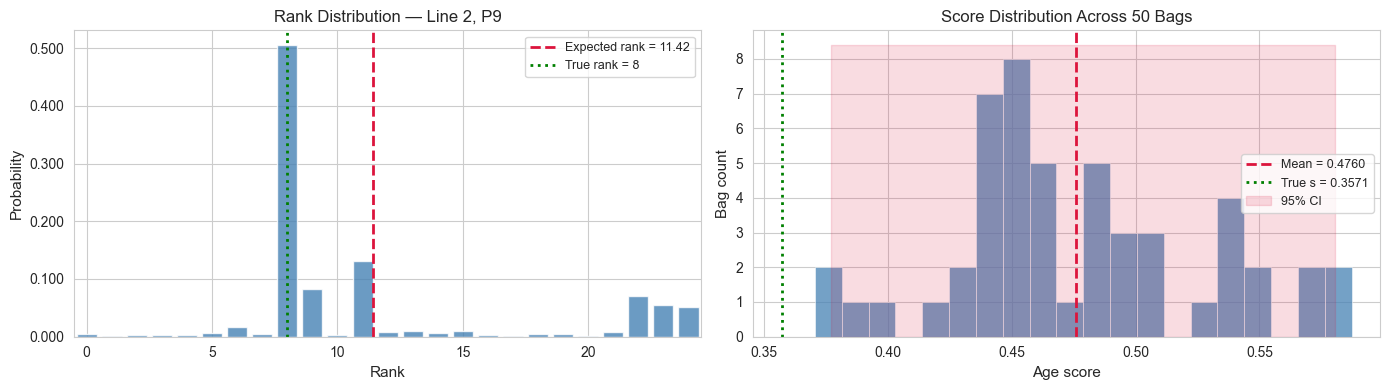

Saved → outputs/figures/age_score_distribution.png


In [22]:
# ── Cell 5 — Visualise rank probability distribution ──────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Derive K from actual model output — not from encoder which may disagree
probs    = result['mean_probs']
K_actual = num_classes                 # single source of truth (encoder)
ranks    = np.arange(K_actual)

# Left: rank probability distribution
ax   = axes[0]
bars = ax.bar(ranks, probs, color='steelblue', alpha=0.8, width=0.8)

# Mark expected rank
ax.axvline(result['rank_expected'], color='crimson', lw=2,
           linestyle='--', label=f"Expected rank = {result['rank_expected']:.2f}")

# Mark true rank — encoder and model now share num_classes, no clamp needed.
true_rank = encoder.score_to_rank(s_true)
ax.axvline(true_rank, color='green', lw=2,
           linestyle=':', label=f"True rank = {true_rank}")

ax.set_xlabel('Rank', fontsize=11)
ax.set_ylabel('Probability', fontsize=11)
ax.set_title(f'Rank Distribution — Line {CELL_LINE}, P{PASSAGE}', fontsize=12)
ax.legend(fontsize=9)
ax.set_xlim(-0.5, K_actual - 0.5)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.3f'))

# Right: per-bag score distribution
ax2 = axes[1]
ax2.hist(result['all_scores'], bins=20, color='steelblue', alpha=0.75,
         edgecolor='white', linewidth=0.5)
ax2.axvline(result['score'], color='crimson', lw=2,
            linestyle='--', label=f"Mean = {result['score']:.4f}")
ax2.axvline(s_true, color='green', lw=2,
            linestyle=':', label=f"True s = {s_true:.4f}")

# Draw CI shading after histogram so ylim is set
ymax = ax2.get_ylim()[1]
ax2.fill_betweenx([0, ymax],
    result['score_ci_95'][0], result['score_ci_95'][1],
    alpha=0.15, color='crimson', label='95% CI')

ax2.set_xlabel('Age score', fontsize=11)
ax2.set_ylabel('Bag count', fontsize=11)
ax2.set_title('Score Distribution Across 50 Bags', fontsize=12)
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig('../outputs/figures/age_score_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → outputs/figures/age_score_distribution.png")



Trajectory — Spearman ρ = 0.9753  MAE(s) = 0.0453


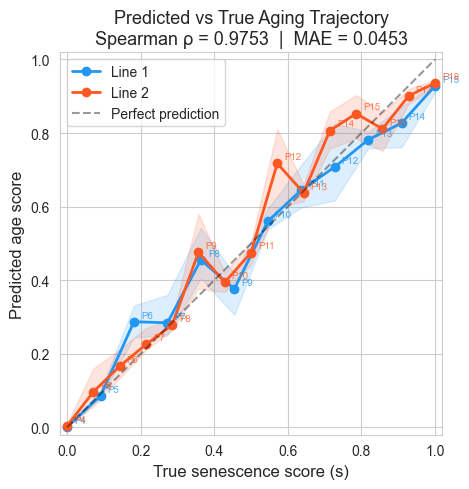

In [27]:
# ── Cell 6 — Full trajectory: predicted vs true for all 27 groups ──────────────
records = []
for (cell_line, passage), grp in labels_df.groupby(['cell_line', 'passage']):
    idx   = grp.index.values
    feats = features_full[idx]
    wells = grp['well_name'].values
    s_true = float(grp['s'].values[0])

    r = get_age_score(feats, wells, n_bag_samples=50, return_distribution=False)
    records.append({
        'cell_line'  : cell_line,
        'passage'    : passage,
        's_true'     : s_true,
        's_hat'      : r['score'],
        's_hat_std'  : r['score_std'],
        'ci_lo'      : r['score_ci_95'][0],
        'ci_hi'      : r['score_ci_95'][1],
    })

traj = pd.DataFrame(records)
rho, p = spearmanr(traj['s_true'], traj['s_hat'])
mae    = np.mean(np.abs(traj['s_true'] - traj['s_hat']))
print(f"\nTrajectory — Spearman ρ = {rho:.4f}  MAE(s) = {mae:.4f}")

# Plot
fig, ax = plt.subplots(figsize=(10, 5))
colors = {1: '#2196F3', 2: '#FF5722'}

for line in [1, 2]:
    sub = traj[traj['cell_line'] == line].sort_values('s_true')
    ax.plot(sub['s_true'], sub['s_hat'],
            color=colors[line], marker='o', linewidth=2,
            markersize=6, label=f'Line {line}')
    ax.fill_between(sub['s_true'], sub['ci_lo'], sub['ci_hi'],
                    color=colors[line], alpha=0.15)
    for _, row in sub.iterrows():
        ax.annotate(f"P{int(row['passage'])}",
                    (row['s_true'], row['s_hat']),
                    textcoords='offset points', xytext=(5, 3),
                    fontsize=7, color=colors[line], alpha=0.8)

# Identity line
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, linewidth=1.5, label='Perfect prediction')
ax.set_xlabel('True senescence score (s)', fontsize=12)
ax.set_ylabel('Predicted age score', fontsize=12)
ax.set_title(f'Predicted vs True Aging Trajectory\nSpearman ρ = {rho:.4f}  |  MAE = {mae:.4f}',
             fontsize=13)
ax.legend(fontsize=10)
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.set_aspect('equal')
plt.tight_layout()
plt.savefig('../outputs/figures/trajectory_predicted_vs_true.png', dpi=300, bbox_inches='tight')
plt.show()


In [24]:
# ── Cell 7 — Score a NEW sample (treated or otherwise) ────────────────────────
#
# This is the treatment inference pathway.
# Load any CSV with the same feature columns, apply the SAVED scalers,
# and call get_age_score(). The model has no knowledge of passage or line —
# it reads morphology only.

def score_new_sample(
    features_csv_path: str,
    well_col: str = 'well_name',
    n_bag_samples: int = 100,
) -> dict:
    """
    Score cells from a new CSV file (treatment sample, unseen data, etc.)

    The CSV must contain the same feature columns used during training.
    Manual and latent cols are loaded from the pkl files to ensure
    column alignment — order in the CSV does not matter.

    Parameters
    ----------
    features_csv_path : str  — path to raw (unscaled) feature CSV
    well_col          : str  — column name for well identifier
    n_bag_samples     : int  — more samples = more stable score

    Returns
    -------
    result : dict — same as get_age_score()
        Primary output: result['score'] ∈ [0, 1]
        Interpretation:
            0.0 = morphologically youngest (equivalent to earliest passage)
            1.0 = morphologically oldest  (equivalent to senescent passage)
    """
    with open(PROCESSED_DIR / 'manual_cols.pkl', 'rb') as f:
        manual_cols = pickle.load(f)
    with open(PROCESSED_DIR / 'latent_cols.pkl', 'rb') as f:
        latent_cols = pickle.load(f)

    df = pd.read_csv(features_csv_path)

    # Validate columns
    missing_manual = [c for c in manual_cols if c not in df.columns]
    missing_latent = [c for c in latent_cols if c not in df.columns]
    if missing_manual or missing_latent:
        raise ValueError(
            f"Input CSV is missing feature columns:\n"
            f"  Manual: {missing_manual}\n"
            f"  Latent: {missing_latent}"
        )

    # Extract, scale with SAVED scalers, apply block weights
    manual_raw  = df[manual_cols].values.astype(np.float32)
    latent_raw  = df[latent_cols].values.astype(np.float32)

    manual_scaled = scaler_manual.transform(manual_raw).astype(np.float32)
    latent_scaled = scaler_latent.transform(latent_raw).astype(np.float32)

    feats = np.concatenate([
        manual_scaled * w_manual,
        latent_scaled * w_latent
    ], axis=1)

    # Well names for per-well capping
    if well_col in df.columns:
        wells = df[well_col].values.astype(str)
    else:
        # No well info — treat all cells as one well
        wells = np.array(['well_0'] * len(df))
        print(f"  ⚠ '{well_col}' not found — treating all cells as one well")

    result = get_age_score(
        cell_features=feats,
        well_names=wells,
        n_bag_samples=n_bag_samples,
        return_distribution=True,
    )

    print(f"\n{'═'*50}")
    print(f"  Sample       : {Path(features_csv_path).name}")
    print(f"  N cells      : {len(df)}")
    print(f"{'─'*50}")
    print(f"  AGE SCORE    : {result['score']:.4f}")
    print(f"  95% CI       : [{result['score_ci_95'][0]:.4f}, "
          f"{result['score_ci_95'][1]:.4f}]")
    print(f"  Uncertainty  : ±{result['score_std']:.4f}")
    print(f"{'═'*50}")

    return result


# Example usage — replace with your actual treatment CSV path:
# result = score_new_sample('data/raw/treatment_group_A.csv')
# print(f"Age score: {result['score']:.4f}")


In [25]:
# ── Cell 9 — Load NMN treatment data ──────────────────────────────────────────
NMN_FEATURES_PATH = '../data/nmn_treatment/raw/full_dset_nmn.csv'
NMN_LABELS_PATH   = '../data/nmn_treatment/raw/full_dset_nmn_labels.csv'

# Load features and labels
nmn_features_raw = pd.read_csv(NMN_FEATURES_PATH)
nmn_labels       = pd.read_csv(NMN_LABELS_PATH)

# Lowercase column names for consistency with training pipeline
nmn_labels.columns = [c.lower().strip() for c in nmn_labels.columns]

# Enforce correct dtypes
nmn_labels['line'] = nmn_labels['line'].astype(int)
nmn_labels['passage']   = nmn_labels['passage'].astype(int)
nmn_labels['repeat']    = nmn_labels['repeat'].astype(int)
nmn_labels['dose']      = nmn_labels['dose'].astype(float)
nmn_labels['well_name'] = nmn_labels['well_name'].astype(str).str.strip()

# Validate row alignment
assert len(nmn_features_raw) == len(nmn_labels), \
    f"Row mismatch: features={len(nmn_features_raw)}, labels={len(nmn_labels)}"

print(f"NMN dataset loaded:")
print(f"  Cells      : {len(nmn_labels)}")
print(f"  Passages   : {sorted(nmn_labels['passage'].unique())}")
print(f"  Cell lines : {sorted(nmn_labels['line'].unique())}")
print(f"  Doses      : {sorted(nmn_labels['dose'].unique())}")
print(f"  Repeats    : {sorted(nmn_labels['repeat'].unique())}")
print(f"\nGroup counts (cell_line × passage × repeat × dose):")
print(
    nmn_labels.groupby(['line', 'passage', 'repeat', 'dose'])
    .size()
    .reset_index(name='n_cells')
    .to_string(index=False)
)


NMN dataset loaded:
  Cells      : 10013
  Passages   : [np.int64(8)]
  Cell lines : [np.int64(221)]
  Doses      : [np.float64(0.0), np.float64(250.0), np.float64(500.0), np.float64(750.0), np.float64(1000.0), np.float64(1250.0)]
  Repeats    : [np.int64(1), np.int64(2)]

Group counts (cell_line × passage × repeat × dose):
 line  passage  repeat   dose  n_cells
  221        8       1    0.0      695
  221        8       1  250.0      693
  221        8       1  500.0      755
  221        8       1  750.0      765
  221        8       1 1000.0      868
  221        8       1 1250.0      718
  221        8       2    0.0      763
  221        8       2  250.0      817
  221        8       2  500.0      923
  221        8       2  750.0      949
  221        8       2 1000.0      992
  221        8       2 1250.0     1075


In [26]:
# ── Cell 10 — Scale NMN features with SAVED train scalers ─────────────────────
# Load the same feature column lists used during training
with open(PROCESSED_DIR / 'manual_cols.pkl', 'rb') as f:
    manual_cols = pickle.load(f)
with open(PROCESSED_DIR / 'latent_cols.pkl', 'rb') as f:
    latent_cols = pickle.load(f)

# Validate all required columns are present
missing_manual = [c for c in manual_cols if c not in nmn_features_raw.columns]
missing_latent = [c for c in latent_cols if c not in nmn_features_raw.columns]
if missing_manual or missing_latent:
    raise ValueError(
        f"NMN feature CSV is missing columns:\n"
        f"  Manual: {missing_manual}\n"
        f"  Latent: {missing_latent}"
    )

# Extract in training column order — order must match exactly
nmn_manual_raw = nmn_features_raw[manual_cols].values.astype(np.float32)
nmn_latent_raw = nmn_features_raw[latent_cols].values.astype(np.float32)

# Apply train-fitted scalers — never refit on new data
nmn_manual_scaled = scaler_manual.transform(nmn_manual_raw).astype(np.float32)
nmn_latent_scaled = scaler_latent.transform(nmn_latent_raw).astype(np.float32)

# Apply block weights
if feature_set == 'latent':
        nmn_features_full = nmn_latent_scaled * w_latent
elif feature_set == 'manual':
    nmn_features_full = nmn_manual_scaled * w_manual
else:
    nmn_features_full = np.concatenate([
        nmn_manual_scaled * w_manual,
        nmn_latent_scaled * w_latent
    ], axis=1).astype(np.float32)

    # OOD check — warn if new data falls far outside training distribution
    max_z_manual = np.abs(nmn_manual_scaled).max()
    max_z_latent = np.abs(nmn_latent_scaled).max()
    print(f"OOD check (train-scaler z-scores):")
    print(f"  Max |z| manual : {max_z_manual:.2f}  "
          f"{'⚠ OOD warning' if max_z_manual > 5 else '✔ OK'}")
    print(f"  Max |z| latent : {max_z_latent:.2f}  "
          f"{'⚠ OOD warning' if max_z_latent > 5 else '✔ OK'}")
    print(f"\nNMN features scaled: {nmn_features_full.shape}")

    # ── Find the extreme z-score features ─────────────────────────────────────────
    manual_z = scaler_manual.transform(nmn_manual_raw)

    feature_max_z = pd.DataFrame({
        'feature'  : manual_cols,
        'max_abs_z': np.abs(manual_z).max(axis=0),
        'train_mean': scaler_manual.mean_,
        'train_std' : np.sqrt(scaler_manual.var_),
        'nmn_min'  : nmn_manual_raw.min(axis=0),
        'nmn_max'  : nmn_manual_raw.max(axis=0),
        'nmn_mean' : nmn_manual_raw.mean(axis=0),
    }).sort_values('max_abs_z', ascending=False)

    print(f"\nTop 10 most extreme manual features in NMN data:")
    print(feature_max_z.head(10).to_string(index=False))



ValueError: NMN feature CSV is missing columns:
  Manual: ['kurt_10', 'skew_20per_10', 'var_40per_11', 'mean_12', 'rawIntDen_12', 'var_20per_12', 'kurt_20per_12', 'mean_13', 'rawIntDen_13', 'skew_40per_13', 'mean_14', 'rawIntDen_14', 'var_20per_14', 'kurt_20per_14', 'ratio3', 'ratio4', 'ratio8', 'num_neighbours']
  Latent: []

In [ ]:
  # ── Cell 11 — Score every Repeat × Dose group ─────────────────────────────────
from scipy.stats import mannwhitneyu

records = []

groups = nmn_labels.groupby(['line', 'passage', 'repeat', 'dose'])

for (cell_line, passage, repeat, dose), grp in tqdm(groups, desc="Scoring NMN groups"):
    idx        = grp.index.values
    group_feats = nmn_features_full[idx]
    well_names  = grp['well_name'].values

    result = get_age_score(
        cell_features=group_feats,
        well_names=well_names,
        n_bag_samples=50,
        cells_per_bag=min(50, len(idx)),   # adapt to group size
        return_distribution=True,
    )

    records.append({
        'cell_line'   : cell_line,
        'passage'     : passage,
        'repeat'      : repeat,
        'dose'        : dose,
        'n_cells'     : len(idx),
        'age_score'   : result['score'],
        'score_std'   : result['score_std'],
        'ci_lo'       : result['score_ci_95'][0],
        'ci_hi'       : result['score_ci_95'][1],
        'all_scores'  : result['all_scores'],   # keep for pairwise testing
    })

nmn_results = pd.DataFrame(records)

# Separate display df (without the array column)
nmn_display = nmn_results.drop(columns='all_scores').copy()
nmn_display['age_score'] = nmn_display['age_score'].round(4)
nmn_display['score_std'] = nmn_display['score_std'].round(4)
nmn_display['ci_lo']     = nmn_display['ci_lo'].round(4)
nmn_display['ci_hi']     = nmn_display['ci_hi'].round(4)

print(f"\nNMN Age Scores by Group:")
print(nmn_display.sort_values(
    ['cell_line', 'passage', 'repeat', 'dose']
).to_string(index=False))

# Save
nmn_display.to_csv('../outputs/logs/latent/nmn_age_scores.csv', index=False)
print(f"\nSaved → outputs/logs/latent/nmn_age_scores.csv")


In [ ]:
# ── Cell 12 — Statistical comparison: treated vs control per passage/repeat ────
comparison_records = []

# For each passage × repeat × cell_line, compare each dose against dose=0
for (cell_line, passage, repeat), subset in nmn_results.groupby(
    ['cell_line', 'passage', 'repeat']
):
    control = subset[subset['dose'] == 0]
    if len(control) == 0:
        print(f"  ⚠ No control (dose=0) for Line {cell_line} P{passage} R{repeat}")
        continue

    ctrl_scores = control['all_scores'].values[0]
    ctrl_mean   = float(control['age_score'].values[0])

    treated = subset[subset['dose'] != 0]
    for _, row in treated.iterrows():
        treat_scores = row['all_scores']
        stat, p      = mannwhitneyu(ctrl_scores, treat_scores,
                                    alternative='two-sided')
        delta        = row['age_score'] - ctrl_mean  # negative = rejuvenation

        comparison_records.append({
            'cell_line'    : cell_line,
            'passage'      : passage,
            'repeat'       : repeat,
            'dose'         : row['dose'],
            'ctrl_score'   : round(ctrl_mean, 4),
            'treat_score'  : round(row['age_score'], 4),
            'delta'        : round(delta, 4),
            'direction'    : 'younger' if delta < 0 else 'older',
            'mw_stat'      : round(float(stat), 2),
            'p_value'      : round(float(p), 6),
            'significant'  : p < 0.05,
        })

comparisons = pd.DataFrame(comparison_records).sort_values(
    ['cell_line', 'passage', 'repeat', 'dose']
).reset_index(drop=True)

print(f"\nNMN Treatment Comparisons (vs Dose=0 control):")
print(comparisons.drop(columns='mw_stat').to_string(index=False))
comparisons.to_csv('../outputs/logs/nmn_comparisons.csv', index=False)
print(f"\nSaved → outputs/logs/nmn_comparisons.csv")


In [ ]:
# ── Cell 13 — Visualise: age score vs dose, faceted by passage × cell_line ────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

fig_groups = nmn_results.groupby(['cell_line', 'passage'])
n_panels   = len(fig_groups)
ncols      = min(3, n_panels)
nrows      = int(np.ceil(n_panels / ncols))

fig, axes = plt.subplots(nrows, ncols,
                         figsize=(5 * ncols, 4 * nrows),
                         squeeze=False)
axes_flat = axes.flatten()

colors = plt.cm.viridis(np.linspace(0.2, 0.85, nmn_results['repeat'].nunique()))
repeat_list = sorted(nmn_results['repeat'].unique())

for ax_idx, ((cell_line, passage), grp) in enumerate(fig_groups):
    ax = axes_flat[ax_idx]

    for r_idx, repeat in enumerate(repeat_list):
        rep_grp = grp[grp['repeat'] == repeat].sort_values('dose')
        if len(rep_grp) == 0:
            continue

        doses  = rep_grp['dose'].values
        scores = rep_grp['age_score'].values
        ci_lo  = rep_grp['ci_lo'].values
        ci_hi  = rep_grp['ci_hi'].values

        ax.plot(doses, scores, marker='o', linewidth=2,
                color=colors[r_idx], label=f'Repeat {repeat}')
        ax.fill_between(doses, ci_lo, ci_hi,
                        alpha=0.15, color=colors[r_idx])

    ax.set_title(f'Line {cell_line}  |  Passage {passage}', fontsize=11)
    ax.set_xlabel('NMN Dose', fontsize=9)
    ax.set_ylabel('Age Score', fontsize=9)
    ax.set_ylim(0, 1)
    ax.axhline(grp[grp['dose'] == 0]['age_score'].mean(),
               color='grey', linestyle='--', linewidth=1, alpha=0.6,
               label='Control')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

# Hide unused panels
for ax_idx in range(n_panels, len(axes_flat)):
    axes_flat[ax_idx].set_visible(False)

plt.suptitle('NMN Treatment — Predicted Age Score by Dose',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('../outputs/figures/nmn_age_scores_by_dose.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved → outputs/figures/nmn_age_scores_by_dose.png")


In [ ]:
# ── UMAP of model geometry: importance-weighted cell embedding ──────────────────
# Reproduces the model's exact input transform (persisted scalers → block weights),
# then weights each feature axis by normalized mean-|IG|. Plots weighted vs.
# unweighted (standardized) embeddings so the contrast reads as MODEL GEOMETRY,
# not independent data structure.
#
# CAVEAT: importance weights were learned to predict s, so an importance-weighted
# embedding is partly guaranteed to organize along the age axis. The unweighted
# panel is the honest reference. Lowering top_k sharpens this circularity.
import umap  # pip install umap-learn

from src.dataset import load_processed, load_scalers, apply_scalers
from src.utils import resolve_block_weights

# ── CONFIG ──────────────────────────────────────────────────────────────────────
PROCESSED_DIR = 'data/processed'
IG_SOURCE     = 'baseline_v1_clean'
TOP_K         = None      # None = all features | else int, e.g. 30, 15, 8
N_NEIGHBORS   = 50        # ↑ for global structure, ↓ for local clusters
MIN_DIST      = 0.1
COLOR_BY      = 's'       # 's' (true score) — swap to 's_hat'/'passage'/'cell_line'

# ── 1. Load processed features + persisted (train-fit-only) scalers ──────────────
# FEATURES ARE SCALED AND WEIGHTED IN CELL 2

# Get col names from pd header from the input csvs
lat = pd.read_csv("C:/Users/goofy/PycharmProjects/MILAgeScore/data/processed/features_latent.csv", header=0)


latent_cols = lat.columns.tolist()
feat_names = list(latent_cols)
X_model = features_full
assert X_model.shape[1] == len(feat_names), "feature/name length mismatch"

print(X_model.shape[1])
# ── 2. Build normalized mean-|IG| feature weights ────────────────────────────────
ig_df  = pd.read_csv("C:/Users/goofy/PycharmProjects/MILAgeScore/outputs/logs/latent_only_v1_importance_normalised.csv", index_col=0)
ig_ser = ig_df["global_mean_abs_ig"].reindex(feat_names)   # align to feat_names order
ig_mag = ig_ser.fillna(0).values                           # NaN → 0 for missing features

assert ig_mag.shape[0] == len(feat_names), "IG vector length must match feature count"

# Normalize to max = 1 (keeps relative spacing; sum=1 also fine)
w_ig = ig_mag / (ig_mag.max() + 1e-12)

# ── 3. Optional top-k hard selection ─────────────────────────────────────────────
if TOP_K is not None:
    keep = np.argsort(ig_mag)[::-1][:TOP_K]              # indices of top_k by |IG|
    keep = np.sort(keep)
    X_sel      = X_model[:, keep]
    w_sel      = w_ig[keep]
    names_sel  = [feat_names[i] for i in keep]
    print(f"top_k={TOP_K} → kept features: {names_sel}")
else:
    X_sel, w_sel, names_sel = X_model, w_ig, feat_names
    print(f"top_k=None → using all {X_sel.shape[1]} features")

# ── 4. Two embeddings: importance-weighted vs. unweighted (standardized) ─────────
X_weighted   = X_sel * w_sel[None, :]                    # x̃_ij = w_j · (block·z)_ij
X_unweighted = X_sel                                     # same axes, no IG weighting

def embed(X):
    reducer = umap.UMAP(n_neighbors=N_NEIGHBORS, min_dist=MIN_DIST, metric='euclidean')
    return reducer.fit_transform(X)

emb_w  = embed(X_weighted)
emb_uw = embed(X_unweighted)

# ── 5. Plot side by side ─────────────────────────────────────────────────────
color_vals = labels_df[COLOR_BY].values
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
fig.patch.set_facecolor('white')   # ← figure background

for ax, emb, title in [
    (axes[0], emb_uw, f'Unweighted (standardized)  ·  {X_sel.shape[1]} feats'),
    (axes[1], emb_w,  f'IG-weighted [{IG_SOURCE}]  ·  top_k={TOP_K}'),
]:
    ax.set_facecolor('white')      # ← axes background
    sc = ax.scatter(emb[:, 0], emb[:, 1], c=color_vals, cmap='viridis', s=4, alpha=0.5)
    ax.set_title(title); ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
    fig.colorbar(sc, ax=ax, label=COLOR_BY, fraction=0.046, pad=0.04)

fig.suptitle(f'Model geometry — colored by {COLOR_BY}  (IG: {IG_SOURCE})', fontsize=13)
plt.show()
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white'})